In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

Cargar el dataset:

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Primeros registros:")
print(X.head())

print("\nDimensiones:", X.shape)
print("\nTipos de variables:")
print(X.dtypes)

print("\nEstadísticas descriptivas:")
print(X.describe())

print("\nValores nulos:")
print(X.isnull().sum().sum())

Primeros registros:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dimensiones: (150, 4)

Tipos de variables:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

Estadísticas descriptivas:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000 

Estandarizar los datos:

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos estandarizados:")
print(X_scaled[:5])

Datos estandarizados:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


Construir el dendograma:

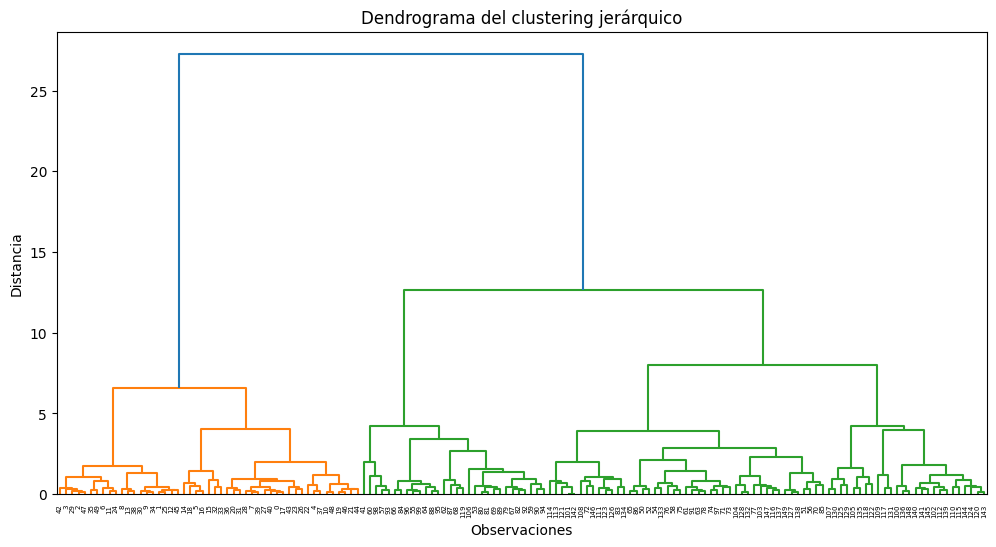

In [4]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrograma del clustering jerárquico")
plt.xlabel("Observaciones")
plt.ylabel("Distancia")
plt.show()

Implementar Agglomerative Clustering:

In [5]:
modelo = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

clusters = modelo.fit_predict(X_scaled)

print("Cantidad de clusters:", len(np.unique(clusters)))
print("\nCantidad de observaciones por cluster:")
print(pd.Series(clusters).value_counts().sort_index())

Cantidad de clusters: 2

Cantidad de observaciones por cluster:
0    101
1     49
Name: count, dtype: int64


Calcular las métricas de evaluación:

In [6]:
silhouette = silhouette_score(X_scaled, clusters)
davies = davies_bouldin_score(X_scaled, clusters)
calinski = calinski_harabasz_score(X_scaled, clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", davies)
print("Calinski-Harabasz Score:", calinski)

Silhouette Score: 0.5770346019475988
Davies-Bouldin Index: 0.5916560992933364
Calinski-Harabasz Score: 240.24566522437965


Aplicar PCA y visualizar los clusters:

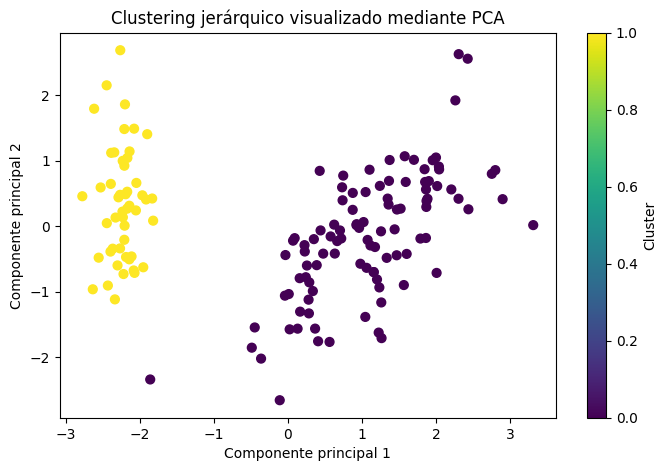

Varianza explicada: [0.72962445 0.22850762]
Varianza total: 0.9581320720000166


In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=40
)

plt.title("Clustering jerárquico visualizado mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Cluster")
plt.show()

print("Varianza explicada:", pca.explained_variance_ratio_)
print("Varianza total:", sum(pca.explained_variance_ratio_))